In [16]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from ucimlrepo import fetch_ucirepo 
import matplotlib.pyplot as plt
import random
from zonolayer import fit_zonolayer, predict_zonolayer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from SLINN import SLINN, midrad
from interval_metrics import interval_metrics, compare_models, benchmark_inference, compute_picp
import time

def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

def build_numpy_feature_extractor(model):
    layer_ops = []

    for module in model.feature_extractor:
        if isinstance(module, nn.Linear):
            W = module.weight.detach().cpu().numpy()
            b = module.bias.detach().cpu().numpy()
            layer_ops.append(("linear", W, b))
        elif isinstance(module, nn.Tanh):
            layer_ops.append(("tanh", None, None))
        elif isinstance(module, nn.ReLU):
            layer_ops.append(("relu", None, None))
        elif isinstance(module, nn.Sigmoid):
            layer_ops.append(("sigmoid", None, None))
        else:
            raise NotImplementedError(
                f"No NumPy equivalent registered for layer type {type(module)}"
            )

    Wr = model.regressor.weight.detach().cpu().numpy()
    br = model.regressor.bias.detach().cpu().numpy()

    def extract(x):
        x = np.asarray(x, dtype=np.float32)
        for kind, W, b in layer_ops:
            if kind == "linear":
                x = x @ W.T + b
            elif kind == "tanh":
                x = np.tanh(x)
            elif kind == "relu":
                x = np.maximum(x, 0)
        features = x
        preds = (features @ Wr.T + br).flatten()
        return preds, features

    return extract

## Heating Load - Energy Dataset

In [17]:
df = pd.read_csv('Data/energy_efficiency_data.csv')
X = df.drop(columns=['Heating_Load', 'Cooling_Load'])
print(X)
y_heating = df['Heating_Load'].values

def intervalise_heating_load(y):
    n = len(y)
    r = np.abs(np.random.normal(loc=0.5, scale=0.25, size=n))
    b = np.random.uniform(low=-1.0, high=1.0, size=n)
    m = y - r + (1 + b) * r
    return pd.DataFrame({"y": y, "y_lower": m - r, "y_upper": m + r})

intervals = intervalise_heating_load(y_heating)

# Split and Normalize
X_train, X_test, y_low_tr, y_low_te, y_up_tr, y_up_te = train_test_split(
    X.values, intervals['y_lower'].values, intervals['y_upper'].values, test_size=0.25, random_state=42
)

X_min, X_max = X_train.min(axis=0), X_train.max(axis=0)
X_train = (X_train - X_min) / (X_max - X_min)
X_test = (X_test - X_min) / (X_max - X_min)
y_mid_tr, y_rad_tr = (y_low_tr + y_up_tr) / 2, (y_up_tr - y_low_tr) / 2
y_mean, y_std = y_mid_tr.mean(), y_mid_tr.std()
Y_train = midrad((y_mid_tr.reshape(-1,1) - y_mean) / y_std, y_rad_tr.reshape(-1,1) / y_std)

# Normalise both bounds
y_low_tr = (y_low_tr - y_mean) / y_std
y_up_tr  = (y_up_tr  - y_mean) / y_std

class RegressionNetwork(nn.Module):
    def __init__(self, input_dim=8, hidden_dim=8, zono_dim=8):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, zono_dim)
        )
        self.regressor = nn.Linear(zono_dim, 1)

    def forward(self, x, return_features=False):
        features = self.feature_extractor(x)
        out = self.regressor(features)
        if return_features:
            return out, features
        return out


def train_centre(x_t, y_lb_t, y_ub_t, epochs=7000, lr=0.01, momentum=0.9, print_every=50):
    y_mid = ((y_lb_t + y_ub_t) / 2).reshape(-1, 1)
    centre_net = RegressionNetwork(input_dim=x_t.shape[1])
    optimizer = torch.optim.SGD(centre_net.parameters(), lr=lr, momentum=momentum, weight_decay=0.0)
    criterion = nn.MSELoss()
    for epoch in range(epochs):
        pred = centre_net(x_t)
        loss = criterion(pred, y_mid)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch+1}: MSE = {loss.item():.6f}")
    return centre_net

# def extract_latent_features(model, x):
#     model.eval()
#     with torch.no_grad():
#         preds, features = model(x, return_features=True)
#     return preds.cpu().numpy(), features.cpu().numpy()

x_t = torch.tensor(X_train, dtype=torch.float32)
y_lb_t = torch.tensor(y_low_tr, dtype=torch.float32)
y_ub_t = torch.tensor(y_up_tr, dtype=torch.float32)

# Zonolayer computation
start = time.perf_counter()
centre_net = train_centre(x_t, y_lb_t, y_ub_t)
centre_net_np = build_numpy_feature_extractor(centre_net)
pred_train, latent_train = centre_net_np(X_train)
zonolayer_fit = fit_zonolayer(latent_train, y_low_tr, y_up_tr)
centre_training_time = time.perf_counter() - start

pred_test, latent_test = centre_net_np(X_test)
zonolayer = predict_zonolayer(zonolayer_fit, latent_test) 

# # Approximation
# upper, lower = train_centre(x_t, y_ub_t, y_ub_t), train_centre(x_t, y_lb_t, y_lb_t)
# upper.eval()
# lower.eval()

# x_test_t = torch.tensor(X_test, dtype=torch.float32)

# with torch.no_grad():
#     upper_pred = upper(x_test_t).numpy().flatten()
#     lower_pred = lower(x_test_t).numpy().flatten()

# # Denormalise predictions
# upper_pred = upper_pred * y_std + y_mean
# lower_pred = lower_pred * y_std + y_mean


start = time.perf_counter()
net = SLINN(nn_input_dim=X_train.shape[1], nn_hdim=8, nn_output_dim=1, L=2, L_rate=0.01, Beta=0.96)
print("Training SLINN...")
net.train(X_train, Y_train, epochs=7000)
slinn_training_time = time.perf_counter() - start

pred = net.predict(X_test, Y_train)


     Relative_Compactness  Surface_Area  Wall_Area  Roof_Area  Overall_Height  \
0                    0.98         514.5      294.0     110.25             7.0   
1                    0.98         514.5      294.0     110.25             7.0   
2                    0.98         514.5      294.0     110.25             7.0   
3                    0.98         514.5      294.0     110.25             7.0   
4                    0.90         563.5      318.5     122.50             7.0   
..                    ...           ...        ...        ...             ...   
763                  0.64         784.0      343.0     220.50             3.5   
764                  0.62         808.5      367.5     220.50             3.5   
765                  0.62         808.5      367.5     220.50             3.5   
766                  0.62         808.5      367.5     220.50             3.5   
767                  0.62         808.5      367.5     220.50             3.5   

     Orientation  Glazing_A

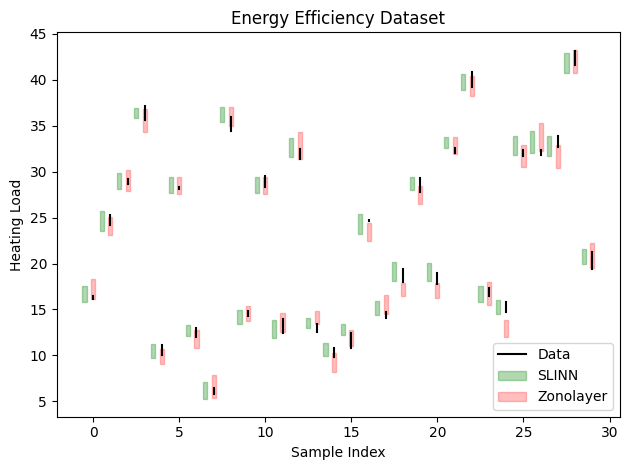


CentreNet + Zonolayer
Inference time: 0.000152 ± 0.000017 s
Per sample: 0.000793 ms
Peak memory: 0.012 MB

SLINN
Inference time: 0.000129 ± 0.000011 s
Per sample: 0.000671 ms
Peak memory: 0.008 MB
                   model  inference_time_s  inference_time_std_s  \
0  CentreNet + Zonolayer          0.000152              0.000017   
1                  SLINN          0.000129              0.000011   

   time_per_sample_ms  peak_memory_mb  
0            0.000793        0.011719  
1            0.000671        0.007812  
                    Dmin    Dmax   Dstar  MAEmid
Zonolayer (test)  0.0588  2.3462  1.3597  0.7847
SLINN (test)      0.0181  1.8600  0.9061  0.5227
                      Dmin      Dmax     Dstar    MAEmid
Zonolayer (test)  0.058806  2.346217  1.359683  0.784656
SLINN (test)      0.018122  1.860043  0.906084  0.522685
CentreNet + Zonolayer training time: 2.890s
SLINN training time: 1.790s
--------------------------------------------------
Zonolayer -> PICP: 39.58%
----------

In [18]:
# Denormalise for plotting
yl_zl = zonolayer["y_lower"] * y_std + y_mean
yu_zl = zonolayer["y_upper"] * y_std + y_mean
midpoint_model = zonolayer["midpoint"] * y_std + y_mean
y_p_mid = (pred.mid.flatten() * y_std) + y_mean
y_p_rad = pred.rad.flatten() * y_std

n_plot = 30
idx = np.sort(np.random.choice(len(X_test), n_plot, replace=False))

plt.figure()

slinn_offset = -0.50   # Shift Left

width = 0.12

for i, val in enumerate(idx):

    # True interval
    plt.plot(
        [i, i],
        [y_low_te[val], y_up_te[val]],
        color='black',
        lw=1.5,
        zorder=3,
        label='Data' if i == 0 else ""
    )

    plt.fill_between(
        [i - width + slinn_offset, i + width + slinn_offset],
        y_p_mid[val] - y_p_rad[val],
        y_p_mid[val] + y_p_rad[val],
        color='green',
        alpha=0.3,
        label='SLINN' if i == 0 else ""
    )

    # ZonoLayer interval
    plt.fill_between(
        [i - width, i + width],
        yl_zl[val],
        yu_zl[val],
        color='red',
        alpha=0.25,
        label='Zonolayer' if i == 0 else ""
    )


# plt.scatter(
#     [i for i in range(n_plot)], 
#     midpoint_model[idx], 
#     marker='+', color='red', zorder=5, s=80, label='ZonoLayer Midpoint'
# )

plt.title("Energy Efficiency Dataset")
plt.xlabel("Sample Index")
plt.ylabel("Heating Load")
plt.legend()
plt.tight_layout()
plt.savefig("PDF/HeatingLoad.pdf", bbox_inches="tight")
plt.show()

# Metrics
def centrenet_predict(X):
    _, feats = centre_net_np(X_test)
    return predict_zonolayer(zonolayer_fit, feats) 

def slinn_predict(X):
    return net.predict(X, Y_train)

zono_benchmark = benchmark_inference(predict_fn=centrenet_predict, X=X_test, name="CentreNet + Zonolayer", n_runs=1000, warmup=100)
slinn_benchmark = benchmark_inference(predict_fn=slinn_predict, X=X_test, name="SLINN", n_runs=1000, warmup=100)
benchmark_df = pd.DataFrame([zono_benchmark, slinn_benchmark])

print(benchmark_df)

zono_metrics = interval_metrics(yl_zl, yu_zl, y_low_te, y_up_te)

slinn_pred_low = y_p_mid - y_p_rad
slinn_pred_up  = y_p_mid + y_p_rad
slinn_metrics = interval_metrics(slinn_pred_low, slinn_pred_up, y_low_te, y_up_te)

results = {
    "Zonolayer (test)": zono_metrics,
    "SLINN (test)": slinn_metrics,
}
comparison_df = compare_models(results)
print(comparison_df)

print(f"CentreNet + Zonolayer training time: {centre_training_time:.3f}s")
print(f"SLINN training time: {slinn_training_time:.3f}s")

zono_picp = compute_picp(y_low_te, y_up_te, yl_zl, yu_zl)

print("-" * 50)
print(f"Zonolayer -> PICP: {zono_picp:.2f}%")
print("-" * 50)

## Concrete Compressive Strength

In [19]:
concrete_compressive_strength = fetch_ucirepo(id=165) 
X = concrete_compressive_strength.data.features 
y = concrete_compressive_strength.data.targets 

def intervalise_cc_strength(y):
    y = np.asarray(y).reshape(-1) 
    delta = np.abs(np.random.normal(loc=2.0, scale=1.0, size=len(y)))
    b = np.random.uniform(low=-1.0, high=1.0, size=len(y))
    m = y + b * delta

    return pd.DataFrame({
        "y": y,
        "y_lower": m - delta,
        "y_upper": m + delta
    })
intervals = intervalise_cc_strength(y)

# Split and Normalize
X_train, X_test, y_low_tr, y_low_te, y_up_tr, y_up_te = train_test_split(
    X.values, intervals['y_lower'].values, intervals['y_upper'].values, test_size=0.3, random_state=42
)

X_min, X_max = X_train.min(axis=0), X_train.max(axis=0)
X_train = (X_train - X_min) / (X_max - X_min)
X_test = (X_test - X_min) / (X_max - X_min)

# Mid/radius
y_mid_tr = (y_low_tr + y_up_tr) / 2
y_rad_tr = (y_up_tr - y_low_tr) / 2

# Min-max scaling parameters from training intervals
y_min = y_low_tr.min()
y_max = y_up_tr.max()

# Scale bounds to [0,1]
y_low_tr = (y_low_tr - y_min) / (y_max - y_min)
y_up_tr  = (y_up_tr  - y_min) / (y_max - y_min)

# Recompute midpoint/radius after scaling
y_mid_tr = (y_low_tr + y_up_tr) / 2
y_rad_tr = (y_up_tr - y_low_tr) / 2

Y_train = midrad(
    y_mid_tr.reshape(-1,1),
    y_rad_tr.reshape(-1,1)
)

In [20]:
class CentreNet(nn.Module):
    def __init__(self, input_dim=8, hidden_dim=24, zono_dim=8):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, zono_dim)
        )
        self.regressor = nn.Linear(zono_dim, 1)

    def forward(self, x, return_features=False):
        features = self.feature_extractor(x)
        out = self.regressor(features)
        if return_features:
            return out, features
        return out


def train_centre(x_t, y_lb_t, y_ub_t, epochs=7000, lr=0.005, momentum=0.96, print_every=50):
    y_mid = ((y_lb_t + y_ub_t) / 2).reshape(-1, 1)
    centre_net = RegressionNetwork(input_dim=x_t.shape[1])
    optimizer = torch.optim.SGD(centre_net.parameters(), lr=lr, momentum=momentum, weight_decay=0.0)
    criterion = nn.MSELoss()
    for epoch in range(epochs):
        pred = centre_net(x_t)
        loss = criterion(pred, y_mid)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch+1}: MSE = {loss.item():.6f}")
    return centre_net


x_t = torch.tensor(X_train, dtype=torch.float32)
y_lb_t = torch.tensor(y_low_tr, dtype=torch.float32)
y_ub_t = torch.tensor(y_up_tr, dtype=torch.float32)

# Zonolayer computation
start = time.perf_counter()
centre_net = train_centre(x_t, y_lb_t, y_ub_t)
centre_net_np = build_numpy_feature_extractor(centre_net)
pred_train, latent_train = centre_net_np(X_train)
zonolayer_fit = fit_zonolayer(latent_train, y_low_tr, y_up_tr)
centre_training_time = time.perf_counter() - start

pred_test, latent_test = centre_net_np(X_test)
zonolayer = predict_zonolayer(zonolayer_fit, latent_test) 


# Denormalise for plotting
yl_zl = zonolayer["y_lower"] * (y_max - y_min) + y_min
yu_zl = zonolayer["y_upper"] * (y_max - y_min) + y_min
midpoint_model = zonolayer["midpoint"] * (y_max - y_min) + y_min


start = time.perf_counter()
net = SLINN(nn_input_dim=X_train.shape[1], nn_hdim=24, nn_output_dim=1, L=3, L_rate=0.005, Beta=0.96)
print("Training SLINN...")
net.train(X_train, Y_train, epochs=12000)
slinn_training_time = time.perf_counter() - start

# Predict & Denormalize
pred = net.predict(X_test, Y_train)
y_p_mid = pred.mid.flatten() * (y_max - y_min) + y_min
y_p_rad = pred.rad.flatten() * (y_max - y_min)

# # Approximation
# upper, lower = train_centre(x_t, y_ub_t, y_ub_t), train_centre(x_t, y_lb_t, y_lb_t)
# upper.eval()
# lower.eval()

# x_test_t = torch.tensor(X_test, dtype=torch.float32)

# with torch.no_grad():
#     upper_pred = upper(x_test_t).numpy().flatten()
#     lower_pred = lower(x_test_t).numpy().flatten()

# # Denormalise predictions
# upper_pred = upper_pred * (y_max - y_min) + y_min
# lower_pred = lower_pred * (y_max - y_min) + y_min

Epoch 50: MSE = 0.062977
Epoch 100: MSE = 0.042354
Epoch 150: MSE = 0.036915
Epoch 200: MSE = 0.035223
Epoch 250: MSE = 0.033612
Epoch 300: MSE = 0.031306
Epoch 350: MSE = 0.028171
Epoch 400: MSE = 0.024488
Epoch 450: MSE = 0.020961
Epoch 500: MSE = 0.018268
Epoch 550: MSE = 0.016691
Epoch 600: MSE = 0.015964
Epoch 650: MSE = 0.015607
Epoch 700: MSE = 0.015385
Epoch 750: MSE = 0.015237
Epoch 800: MSE = 0.015138
Epoch 850: MSE = 0.015070
Epoch 900: MSE = 0.015021
Epoch 950: MSE = 0.014982
Epoch 1000: MSE = 0.014949
Epoch 1050: MSE = 0.014919
Epoch 1100: MSE = 0.014890
Epoch 1150: MSE = 0.014863
Epoch 1200: MSE = 0.014836
Epoch 1250: MSE = 0.014809
Epoch 1300: MSE = 0.014782
Epoch 1350: MSE = 0.014756
Epoch 1400: MSE = 0.014729
Epoch 1450: MSE = 0.014703
Epoch 1500: MSE = 0.014676
Epoch 1550: MSE = 0.014650
Epoch 1600: MSE = 0.014623
Epoch 1650: MSE = 0.014596
Epoch 1700: MSE = 0.014569
Epoch 1750: MSE = 0.014542
Epoch 1800: MSE = 0.014515
Epoch 1850: MSE = 0.014487
Epoch 1900: MSE = 0.0

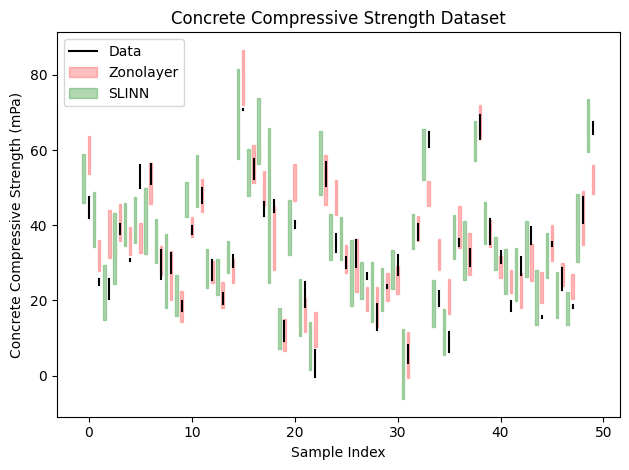


CentreNet + Zonolayer
Inference time: 0.000301 ± 0.000016 s
Per sample: 0.000976 ms
Peak memory: 1.703 MB

SLINN
Inference time: 0.000625 ± 0.000332 s
Per sample: 0.002023 ms
Peak memory: 0.004 MB
                   model  inference_time_s  inference_time_std_s  \
0  CentreNet + Zonolayer          0.000301              0.000016   
1                  SLINN          0.000625              0.000332   

   time_per_sample_ms  peak_memory_mb  
0            0.000976        1.703125  
1            0.002023        0.003906  
                    Dmin     Dmax   Dstar  MAEmid
Zonolayer (test)  1.8515  12.3719  8.3276  6.0241
SLINN (test)      0.5362  12.7785  8.6999  4.1297
                      Dmin       Dmax     Dstar    MAEmid
Zonolayer (test)  1.851495  12.371877  8.327564  6.024070
SLINN (test)      0.536164  12.778489  8.699948  4.129678
CentreNet + Zonolayer training time: 3.809s
SLINN training time: 13.901s


In [21]:
n_plot = 50
idx = np.sort(np.random.choice(len(X_test), n_plot, replace=False))

plt.figure()

slinn_offset = -0.50

width = 0.12 

for i, val in enumerate(idx):
    plt.plot(
        [i, i],
        [y_low_te[val], y_up_te[val]],
        color='black',
        lw=1.5,
        zorder=3,
        label='Data' if i == 0 else ""
    )

    plt.fill_between(
        [i - width, i + width],
        yl_zl[val],
        yu_zl[val],
        color='red',
        alpha=0.25,
        label='Zonolayer' if i == 0 else ""
    )

    plt.fill_between(
        [i - width + slinn_offset, i + width + slinn_offset],
        y_p_mid[val] - y_p_rad[val],
        y_p_mid[val] + y_p_rad[val],
        color='green',
        alpha=0.3,
        label='SLINN' if i == 0 else ""
    )

    # plt.fill_between(
    #     [i - width - slinn_offset, i + width - slinn_offset],
    #     lower_pred[val],
    #     upper_pred[val],
    #     color='blue',
    #     alpha=0.3,
    #     label='Approximation' if i == 0 else ""
    # )

plt.title("Concrete Compressive Strength Dataset")
plt.xlabel("Sample Index")
plt.ylabel("Concrete Compressive Strength (mPa)")
plt.legend()
plt.tight_layout()
plt.savefig("PDF/CCStrength.pdf", bbox_inches="tight")
plt.show()

# Metrics
def centrenet_predict(X):
    _, feats = centre_net_np(X_test)
    return predict_zonolayer(zonolayer_fit, feats) 

def slinn_predict(X):
    return net.predict(X, Y_train)

zono_benchmark = benchmark_inference(predict_fn=centrenet_predict, X=X_test, name="CentreNet + Zonolayer", n_runs=1000, warmup=100)
slinn_benchmark = benchmark_inference(predict_fn=slinn_predict, X=X_test, name="SLINN", n_runs=1000, warmup=100)

benchmark_df = pd.DataFrame([zono_benchmark, slinn_benchmark])
print(benchmark_df)

zono_metrics = interval_metrics(yl_zl, yu_zl, y_low_te, y_up_te)

slinn_pred_low = y_p_mid - y_p_rad
slinn_pred_up  = y_p_mid + y_p_rad
slinn_metrics = interval_metrics(slinn_pred_low, slinn_pred_up, y_low_te, y_up_te)

results = {
    "Zonolayer (test)": zono_metrics,
    "SLINN (test)": slinn_metrics,
}
comparison_df = compare_models(results)
print(comparison_df)

print(f"CentreNet + Zonolayer training time: {centre_training_time:.3f}s")
print(f"SLINN training time: {slinn_training_time:.3f}s")

### Air Quality

In [22]:
def intervalise_airq(y):
    y = np.asarray(y).reshape(-1)
    delta = np.abs(np.random.normal(loc=2.0, scale=1.0, size=len(y)))
    b = np.random.uniform(low=-1.0, high=1.0, size=len(y))
    m = y + b * delta
    return pd.DataFrame({
        "y": y,
        "y_lower": m - delta,
        "y_upper": m + delta
    })


air_quality = fetch_ucirepo(id=360)

X = air_quality.data.features
y_all = air_quality.data.targets
df = pd.concat([X, y_all], axis=1)

print(air_quality.metadata)
print(air_quality.variables)

df = df.replace(-200, np.nan)

# Target: true hourly Benzene concentration
df = df.dropna(subset=["C6H6(GT)"])

feature_cols = [
    "PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)",
    "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"
]
df = df.dropna(subset=feature_cols)

scaler = StandardScaler()
X_norm = pd.DataFrame(
    scaler.fit_transform(df[feature_cols]),
    columns=feature_cols,
    index=df.index
)

y = df["C6H6(GT)"].values
interval_df = intervalise_airq(y).set_index(df.index)
full_df = pd.concat([X_norm, interval_df], axis=1)


y_min = full_df["y_lower"].min()
y_max = full_df["y_upper"].max()

full_df["y_lower_norm"] = (full_df["y_lower"] - y_min) / (y_max - y_min)
full_df["y_upper_norm"] = (full_df["y_upper"] - y_min) / (y_max - y_min)

train_df, test_df = train_test_split(full_df, test_size=0.2, random_state=42)

X_train = train_df[feature_cols].values
X_test = test_df[feature_cols].values
y_low_tr = train_df["y_lower_norm"].values
y_up_tr = train_df["y_upper_norm"].values
y_low_te = test_df["y_lower_norm"].values
y_up_te = test_df["y_upper_norm"].values



class CentreNet(nn.Module):
    def __init__(self, input_dim=8, hidden_dim=12, zono_dim=6):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, zono_dim)
        )
        self.regressor = nn.Linear(zono_dim, 1)

    def forward(self, x, return_features=False):
        features = self.feature_extractor(x)
        out = self.regressor(features)
        if return_features:
            return out, features
        return out


def train_centre(x_t, y_lb_t, y_ub_t, epochs=7000, lr=0.001, momentum=0.9, print_every=50):
    y_mid = ((y_lb_t + y_ub_t) / 2).reshape(-1, 1)
    centre_net = RegressionNetwork(input_dim=x_t.shape[1])
    # Full-batch gradient descent with momentum, no weight decay
    optimizer = torch.optim.SGD(centre_net.parameters(), lr=lr, momentum=momentum, weight_decay=0.0)
    criterion = nn.MSELoss()
    for epoch in range(epochs):
        pred = centre_net(x_t)
        loss = criterion(pred, y_mid)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch+1}: MSE = {loss.item():.6f}")
    return centre_net


x_t = torch.tensor(X_train, dtype=torch.float32)
y_lb_t = torch.tensor(y_low_tr, dtype=torch.float32)
y_ub_t = torch.tensor(y_up_tr, dtype=torch.float32)

# Zonolayer computation
start = time.perf_counter()
centre_net = train_centre(x_t, y_lb_t, y_ub_t)
centre_net_np = build_numpy_feature_extractor(centre_net)
pred_train, latent_train = centre_net_np(X_train)
zonolayer_fit = fit_zonolayer(latent_train, y_low_tr, y_up_tr)
centre_training_time = time.perf_counter() - start

pred_test, latent_test = centre_net_np(X_test)
zonolayer = predict_zonolayer(zonolayer_fit, latent_test) 


yl_zl = zonolayer["y_lower"] * (y_max - y_min) + y_min
yu_zl = zonolayer["y_upper"] * (y_max - y_min) + y_min
midpoint_model = zonolayer["midpoint"] * (y_max - y_min) + y_min


y_mid_tr = (y_low_tr + y_up_tr) / 2
y_rad_tr = (y_up_tr - y_low_tr) / 2

Y_train = midrad(
    y_mid_tr.reshape(-1,1),
    y_rad_tr.reshape(-1,1)
)

start = time.perf_counter()
net = SLINN(nn_input_dim=X_train.shape[1], nn_hdim=12, nn_output_dim=1, L=3, L_rate=0.001, Beta=0.96)
print("Training SLINN...")
net.train(X_train, Y_train, epochs=8000)
slinn_training_time = time.perf_counter() - start

pred = net.predict(X_test, Y_train)
y_p_mid = pred.mid.flatten() * (y_max - y_min) + y_min
y_p_rad = pred.rad.flatten() * (y_max - y_min)

{'uci_id': 360, 'name': 'Air Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/360/air+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/360/data.csv', 'abstract': 'Contains the responses of a gas multisensor device deployed on the field in an Italian city. Hourly responses averages are recorded along with gas concentrations references from a certified analyzer. ', 'area': 'Computer Science', 'tasks': ['Regression'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 9358, 'num_features': 15, 'feature_types': ['Real'], 'demographics': [], 'target_col': None, 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2008, 'last_updated': 'Sun Mar 10 2024', 'dataset_doi': '10.24432/C59K5F', 'creators': ['Saverio Vito'], 'intro_paper': {'ID': 420, 'type': 'NATIVE', 'title': 'On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario', 'authors': 

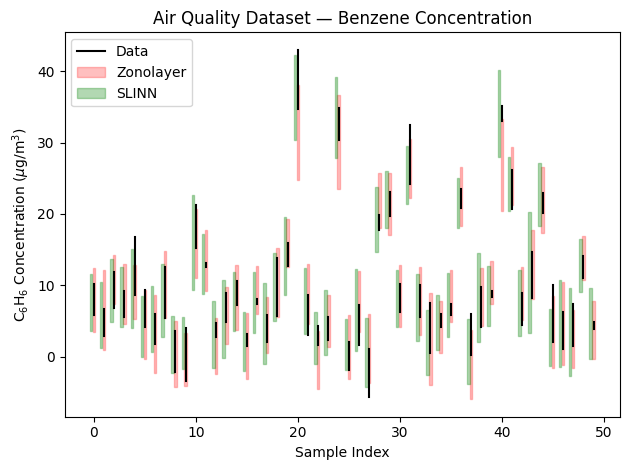


CentreNet + Zonolayer
Inference time: 0.084196 ± 0.003866 s
Per sample: 0.046802 ms
Peak memory: 296.152 MB

SLINN
Inference time: 0.081249 ± 0.002330 s
Per sample: 0.045163 ms
Peak memory: 197.434 MB
                   model  inference_time_s  inference_time_std_s  \
0  CentreNet + Zonolayer          0.084196              0.003866   
1                  SLINN          0.081249              0.002330   

   time_per_sample_ms  peak_memory_mb  
0            0.046802      296.152344  
1            0.045163      197.433594  
                   Dmin    Dmax   Dstar  MAEmid
Zonolayer (test)  0.028  8.1405  4.1471  1.6675
SLINN (test)      0.000  7.9157  3.9085  0.9883
                      Dmin      Dmax     Dstar    MAEmid
Zonolayer (test)  0.027951  8.140507  4.147052  1.667544
SLINN (test)      0.000000  7.915673  3.908506  0.988290
CentreNet + Zonolayer training time: 6.286s
SLINN training time: 43.578s


In [23]:
y_low_te_denorm = np.ravel(y_low_te * (y_max - y_min) + y_min)
y_up_te_denorm  = np.ravel(y_up_te * (y_max - y_min) + y_min)

# Predictions as 1-D arrays
yl_zl, yu_zl = np.ravel(yl_zl), np.ravel(yu_zl)
slinn_pred_low = np.ravel(y_p_mid - y_p_rad)
slinn_pred_up  = np.ravel(y_p_mid + y_p_rad)

n_plot = 50
rng = np.random.default_rng(42)
idx = np.sort(rng.choice(len(X_test), n_plot, replace=False))

plt.figure()

slinn_offset = -0.28
width = 0.12

for i, val in enumerate(idx):
    plt.plot(
        [i, i],
        [y_low_te_denorm[val], y_up_te_denorm[val]],
        color='black', lw=1.5, zorder=3,
        label='Data' if i == 0 else ""
    )
    plt.fill_between(
        [i - width, i + width],
        yl_zl[val], yu_zl[val],
        color='red', alpha=0.25,
        label='Zonolayer' if i == 0 else ""
    )
    plt.fill_between(
        [i - width + slinn_offset, i + width + slinn_offset],
        slinn_pred_low[val], slinn_pred_up[val],
        color='green', alpha=0.3,
        label='SLINN' if i == 0 else ""
    )

plt.title("Air Quality Dataset — Benzene Concentration")
plt.xlabel("Sample Index")
plt.ylabel(r"C$_6$H$_6$ Concentration ($\mu$g/m$^3$)")
plt.legend()
plt.tight_layout()
plt.savefig("PDF/AirQualityBenzene.pdf", bbox_inches="tight")
plt.show()

# Inference benchmarks
def centrenet_predict(X):
    _, feats = centre_net_np(X)
    return predict_zonolayer(zonolayer_fit, feats)

def slinn_predict(X):
    return net.predict(X, Y_train)

zono_benchmark = benchmark_inference(predict_fn=centrenet_predict, X=X_test, name="CentreNet + Zonolayer", n_runs=1000, warmup=100)
slinn_benchmark = benchmark_inference(predict_fn=slinn_predict, X=X_test, name="SLINN", n_runs=1000, warmup=100)
print(pd.DataFrame([zono_benchmark, slinn_benchmark]))

# Metrics: predictions and targets both in original units
zono_metrics = interval_metrics(yl_zl, yu_zl, y_low_te_denorm, y_up_te_denorm)
slinn_metrics = interval_metrics(slinn_pred_low, slinn_pred_up, y_low_te_denorm, y_up_te_denorm)

comparison_df = compare_models({
    "Zonolayer (test)": zono_metrics,
    "SLINN (test)": slinn_metrics,
})
print(comparison_df)

print(f"CentreNet + Zonolayer training time: {centre_training_time:.3f}s")
print(f"SLINN training time: {slinn_training_time:.3f}s")

### Fuel Prediction

In [24]:
def intervalise_airq(y):
    y = np.asarray(y).reshape(-1)
    delta = np.abs(np.random.normal(loc=2.0, scale=1.0, size=len(y)))
    b = np.random.uniform(low=-1.0, high=1.0, size=len(y))
    m = y + b * delta

    return pd.DataFrame({
        "y": y,
        "y_lower": m - delta,
        "y_upper": m + delta
    })



auto_mpg = fetch_ucirepo(id=9)
X = auto_mpg.data.features
y_all = auto_mpg.data.targets

# Combine features and target
df = pd.concat([X, y_all], axis=1)

print(auto_mpg.metadata)
print(auto_mpg.variables)
# Auto MPG contains missing horsepower values
df = df.dropna()
feature_cols = [
    "displacement",
    "cylinders",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin"
]

target_col = "mpg"

scaler = StandardScaler()

X_norm = pd.DataFrame(
    scaler.fit_transform(df[feature_cols]),
    columns=feature_cols,
    index=df.index
)

y = df[target_col].values

interval_df = intervalise_airq(y)

# Keep the same index as df
interval_df.index = df.index

full_df = pd.concat([X_norm, interval_df], axis=1)
y_min = full_df["y_lower"].min()
y_max = full_df["y_upper"].max()

full_df["y_lower_norm"] = (
    (full_df["y_lower"] - y_min)
    / (y_max - y_min)
)

full_df["y_upper_norm"] = (
    (full_df["y_upper"] - y_min)
    / (y_max - y_min)
)

train_df, test_df = train_test_split(
    full_df,
    test_size=0.2,
    random_state=42
)


X_train = train_df[feature_cols].values
X_test = test_df[feature_cols].values

y_low_tr = train_df["y_lower_norm"].values
y_up_tr = train_df["y_upper_norm"].values

y_low_te = test_df["y_lower_norm"].values
y_up_te = test_df["y_upper_norm"].values


print("\nTraining data:")
print("X_train:", X_train.shape)
print("y_low_tr:", y_low_tr.shape)
print("y_up_tr:", y_up_tr.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_low_te:", y_low_te.shape)
print("y_up_te:", y_up_te.shape)


class CentreNet(nn.Module):
    def __init__(self, input_dim=7, hidden_dim=12, zono_dim=7):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, zono_dim)
        )

        self.regressor = nn.Linear(zono_dim, 1)

    def forward(self, x, return_features=False):
        features = self.feature_extractor(x)
        out = self.regressor(features)

        if return_features:
            return out, features

        return out

def train_centre(x_t, y_lb_t, y_ub_t, epochs=7000, lr=0.001, momentum=0.9, print_every=50):
    y_mid = ((y_lb_t + y_ub_t) / 2).reshape(-1, 1)
    centre_net = RegressionNetwork(input_dim=x_t.shape[1])
    # Full-batch gradient descent with momentum, no weight decay
    optimizer = torch.optim.SGD(centre_net.parameters(), lr=lr, momentum=momentum, weight_decay=0.0)
    criterion = nn.MSELoss()
    for epoch in range(epochs):
        pred = centre_net(x_t)
        loss = criterion(pred, y_mid)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch+1}: MSE = {loss.item():.6f}")
    return centre_net

def extract_latent_features(model, x_t):
    model.eval()
    with torch.no_grad():
        pred, features = model(x_t, return_features=True)

    return (
        pred.numpy().flatten(),
        features.numpy()
    )


x_t = torch.tensor(
    X_train,
    dtype=torch.float32
)

y_lb_t = torch.tensor(
    y_low_tr,
    dtype=torch.float32
)

y_ub_t = torch.tensor(
    y_up_tr,
    dtype=torch.float32
)


# Zonolayer computation
start = time.perf_counter()
centre_net = train_centre(x_t, y_lb_t, y_ub_t)
centre_net_np = build_numpy_feature_extractor(centre_net)
pred_train, latent_train = centre_net_np(X_train)
zonolayer_fit = fit_zonolayer(latent_train, y_low_tr, y_up_tr)
centre_training_time = time.perf_counter() - start

pred_test, latent_test = centre_net_np(X_test)
zonolayer = predict_zonolayer(zonolayer_fit, latent_test) 


yl_zl = (
    zonolayer["y_lower"]
    * (y_max - y_min)
    + y_min
)

yu_zl = (
    zonolayer["y_upper"]
    * (y_max - y_min)
    + y_min
)

midpoint_model = (
    zonolayer["midpoint"]
    * (y_max - y_min)
    + y_min
)

y_mid_tr = (
    y_low_tr + y_up_tr
) / 2

y_rad_tr = (
    y_up_tr - y_low_tr
) / 2


Y_train = midrad(
    y_mid_tr.reshape(-1, 1),
    y_rad_tr.reshape(-1, 1)
)


start = time.perf_counter()
net = SLINN(
    nn_input_dim=X_train.shape[1],
    nn_hdim=12,
    nn_output_dim=1,
    L=3,
    L_rate=0.001,
    Beta=0.96
)
print("\nTraining SLINN...")
net.train(X_train, Y_train, epochs=6000)
slinn_training_time = time.perf_counter() - start
pred = net.predict(X_test, Y_train)

y_p_mid = (
    pred.mid.flatten()
    * (y_max - y_min)
    + y_min
)

y_p_rad = (
    pred.rad.flatten()
    * (y_max - y_min)
)

# Prediction interval
y_p_low = y_p_mid - y_p_rad
y_p_up = y_p_mid + y_p_rad


{'uci_id': 9, 'name': 'Auto MPG', 'repository_url': 'https://archive.ics.uci.edu/dataset/9/auto+mpg', 'data_url': 'https://archive.ics.uci.edu/static/public/9/data.csv', 'abstract': 'Revised from CMU StatLib library, data concerns city-cycle fuel consumption', 'area': 'Other', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 398, 'num_features': 7, 'feature_types': ['Real', 'Categorical', 'Integer'], 'demographics': [], 'target_col': ['mpg'], 'index_col': ['car_name'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1993, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5859H', 'creators': ['R. Quinlan'], 'intro_paper': None, 'additional_info': {'summary': 'This dataset is a slightly modified version of the dataset provided in the StatLib library.  In line with the use by Ross Quinlan (1993) in predicting the attribute "mpg", 8 of the original instances were removed because they had unknown values for th

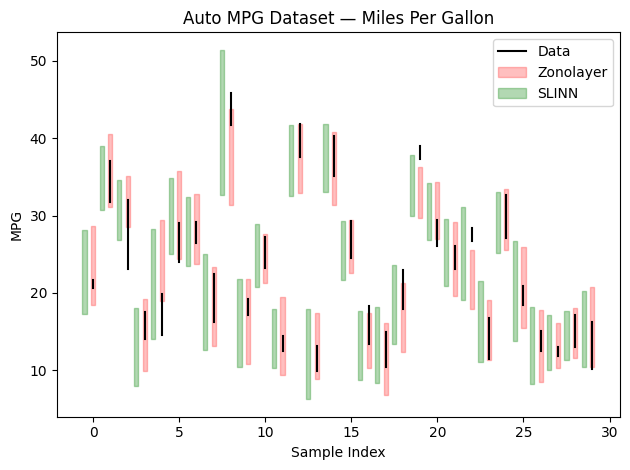


CentreNet + Zonolayer
Inference time: 0.000061 ± 0.000005 s
Per sample: 0.000776 ms
Peak memory: 0.008 MB

SLINN
Inference time: 0.000064 ± 0.000008 s
Per sample: 0.000806 ms
Peak memory: 0.008 MB
                   model  inference_time_s  inference_time_std_s  \
0  CentreNet + Zonolayer          0.000061              0.000005   
1                  SLINN          0.000064              0.000008   

   time_per_sample_ms  peak_memory_mb  
0            0.000776        0.007812  
1            0.000806        0.007812  
                    Dmin    Dmax   Dstar  MAEmid
Zonolayer (test)  0.0663  8.8638  4.8281  2.3614
SLINN (test)      0.0144  9.2317  5.1502  2.1476
                      Dmin      Dmax     Dstar    MAEmid
Zonolayer (test)  0.066338  8.863842  4.828070  2.361438
SLINN (test)      0.014360  9.231716  5.150238  2.147580
CentreNet + Zonolayer training time: 2.703s
SLINN training time: 1.933s


In [25]:
y_low_te_denorm = (y_low_te * (y_max - y_min) + y_min)
y_up_te_denorm = (y_up_te * (y_max - y_min) + y_min)

n_plot = 30

idx = np.sort(
    np.random.choice(
        len(X_test),
        n_plot,
        replace=False
    )
)

plt.figure()
slinn_offset = -0.50
width = 0.12


for i, val in enumerate(idx):
    plt.plot(
        [i, i],
        [
            y_low_te_denorm[val],
            y_up_te_denorm[val]
        ],
        color="black",
        lw=1.5,
        zorder=3,
        label="Data" if i == 0 else ""
    )

    plt.fill_between(
        [i - width, i + width],
        yl_zl[val],
        yu_zl[val],
        color="red",
        alpha=0.25,
        label="Zonolayer" if i == 0 else ""
    )


    plt.fill_between(
        [
            i - width + slinn_offset,
            i + width + slinn_offset
        ],
        y_p_mid[val] - y_p_rad[val],
        y_p_mid[val] + y_p_rad[val],
        color="green",
        alpha=0.3,
        label="SLINN" if i == 0 else ""
    )


plt.title(
    "Auto MPG Dataset — Miles Per Gallon"
)

plt.xlabel("Sample Index")
plt.ylabel("MPG")
plt.legend()
plt.tight_layout()
plt.savefig("PDF/AutoMPG.pdf",bbox_inches="tight")
plt.show()

# Metrics
def centrenet_predict(X):
    _, feats = centre_net_np(X)
    return predict_zonolayer(zonolayer_fit, feats) 

def slinn_predict(X):
    return net.predict(X, Y_train)

zono_benchmark = benchmark_inference(predict_fn=centrenet_predict, X=X_test, name="CentreNet + Zonolayer", n_runs=1000, warmup=100)
slinn_benchmark = benchmark_inference(predict_fn=slinn_predict, X=X_test, name="SLINN", n_runs=1000, warmup=100)
benchmark_df = pd.DataFrame([zono_benchmark, slinn_benchmark])

print(benchmark_df)

y_true_low = np.ravel(y_low_te_denorm)
y_true_up  = np.ravel(y_up_te_denorm)

zono_metrics = interval_metrics(
    np.ravel(yl_zl), np.ravel(yu_zl), y_true_low, y_true_up
)

slinn_pred_low = np.ravel(y_p_mid - y_p_rad)
slinn_pred_up  = np.ravel(y_p_mid + y_p_rad)
slinn_metrics = interval_metrics(
    slinn_pred_low, slinn_pred_up, y_true_low, y_true_up
)

results = {
    "Zonolayer (test)": zono_metrics,
    "SLINN (test)": slinn_metrics,
}
comparison_df = compare_models(results)
print(comparison_df)

print(f"CentreNet + Zonolayer training time: {centre_training_time:.3f}s")
print(f"SLINN training time: {slinn_training_time:.3f}s")